# GradTree experiments: all datasets, GradTree-only plots

Train the PyTorch GradTree on **Adult, Echocardiogram, Iris, Spambase, and Wine**, then produce GradTree-only versions of the reference figures:

1. **Feature-selection ablation** — ST entmax vs ST softmax vs sparsemax.
2. **Main results** — test macro F1, tree size after pruning, and overfitting.
3. **Depth sweep** — test macro F1 and tree size vs maximum depth.

CART and Random Forest are intentionally excluded.

## Before running

- Run the notebook from the repository root, or set `PROJECT_ROOT` manually after the imports cell.
- Install dependencies from the repository root:
  ```bash
  pip install -r model/sunny/requirements.txt
  ```
  On Colab, torch is usually preinstalled, so `pip install -q entmax` is often enough.
- All five datasets need `preprocess/<dataset>_output/seed_42` through `seed_51`. The dataset-check cell reports anything missing.

## Quick vs paper protocol

`QUICK_RUN = True` uses 2 seeds and short training so you can validate the notebook end-to-end. Set `QUICK_RUN = False` for the paper protocol:

```text
10 seeds (42–51), 10,000 max epochs, patience 200, 3 restarts
```

Every run is cached in `model/sunny/results/runs.csv`, scoped to the current protocol, so interrupted sweeps resume from completed rows without mixing quick and paper results.

## Parallel execution (`JOBS`)

Trials are independent — no shared parameters, no shared data, no shared random state — so `JOBS` of them train at once in separate processes:

```python
JOBS = 4     # trials in flight
THREADS = 1  # PyTorch threads inside each worker
```

- **`JOBS = 1`** trains in this kernel (`THREADS` then defaults to half the cores). This is the old behaviour.
- **`JOBS > 1`** starts one worker process per trial. Each worker consciously gets **one** thread: four processes × eight OpenMP threads on eight cores is slower than one process with eight threads. One thread per process, one process per core.
- The training body lives in `model/sunny/experiments.py`, not in a cell: a worker can only re-import a function that lives in an importable module. That is also why `model/myat/train.py` can offer `--jobs` and a notebook-defined function cannot.
- **CPU vs GPU:** the GradTree step is launch-bound (small tensors, entmax bisection, a `float(loss)` sync per batch), so a CPU run and a GPU run take about the same time per trial. On a CPU with *N* cores, `JOBS ≈ N` gives close to an *N*-way speedup on wall clock. On a single GPU, workers *share* the device instead of each getting one, so expect roughly 1.5–2.5× rather than `JOBS`×. If `jobs=4, device="cuda"` is not clearly faster than `jobs=1`, switch `DEVICE` to `"cpu"`.
- **Process start method:** `spawn` (a fresh interpreter per worker). It is safe in a notebook — forking a threaded kernel can deadlock — and required with CUDA, since a CUDA context must never be forked. The import cost is paid once per worker, not once per trial. Override with `runtime["start_method"]`.
- Rows are appended to `runs.csv` as each worker finishes, so an interrupted sweep resumes from the cache.
- Total wall clock ≈ (sum of the individual trial times) ÷ `JOBS`. The recorded `fit_seconds` column tells you the real per-trial cost for your hardware.

## Scope notes

- The model supports `entmax`, `softmax`, and `sparsemax`. The paper's Gumbel-softmax and temperature-annealing variants are not implemented here.
- Paper references come from Tables 1/2 (test macro F1), 9 (tree size), 12 (settings and tuned depth), and 5 (ablation).
- Each trial uses the test split from its data seed (42 + trial), with model seed 42. Per-dataset results are mean ± std over trials; the paper does not average macro F1 across datasets.

In [ ]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter, ScalarFormatter
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "model" / "sunny").is_dir() and (candidate / "preprocess").is_dir():
            return candidate
    return start


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from model.sunny.config import GradTreeConfig
from model.sunny.data import load_dataset
from model.sunny.gradtree import GradTree
from model.sunny.metrics import macro_f1_score
from model.sunny.trainer import GradTreeTrainer
from model.sunny.experiments import (
    DATASETS,
    DATASET_LABELS,
    PAPER_SETTINGS,
    PAPER_TEST_F1,
    PAPER_TREE_SIZE,
    resolve_depth,
    run_tasks,
)

print("Project root:", PROJECT_ROOT)
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

In [ ]:
import hashlib
import os

# The GradTree step is launch-bound, not compute-bound: a CPU trial and a GPU
# trial take about the same time.  With JOBS > 1 all workers share the single
# GPU, so "cpu" with JOBS = cores is usually the faster path for a full sweep.
# Benchmark on wine first (10 x ~60 s): compare DEVICE="cpu", JOBS=4 against
# DEVICE="cuda", JOBS=2 before committing to the paper protocol.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Trials are independent, so they run in separate processes, one (dataset, seed)
# trial per worker.  Set JOBS = 1 to train sequentially in this kernel.
# Each worker gets THREADS PyTorch threads: with JOBS > 1 give every worker a
# single thread, otherwise they fight over the same cores.
JOBS = max(1, min(4, os.cpu_count() or 1))
THREADS = 1 if JOBS > 1 else max(1, (os.cpu_count() or 2) // 2)

# Quick mode validates the notebook; set False for the paper protocol.
QUICK_RUN = False
RUN_MAIN = True
RUN_ABLATION = True
RUN_DEPTH_SWEEP = True   # expensive; set False to skip the third figure

if QUICK_RUN:
    TRIAL_SEEDS = [42, 43]
    EPOCHS = 30
    PATIENCE = 5
    RESTARTS = 0
else:
    TRIAL_SEEDS = list(range(42, 52))
    EPOCHS = 10_000
    PATIENCE = 200
    RESTARTS = 3

# DATASETS, DATASET_LABELS, PAPER_SETTINGS, PAPER_TEST_F1 and PAPER_TREE_SIZE
# are imported from model/sunny/experiments.py: the worker processes import that
# module too, so both sides must share one definition.

# Appendix C, Table 12: optimized per-dataset settings.
ABLATION_DATASETS = DATASETS # ["echocardiogram", "iris", "wine"]
ABLATION_ACTIVATIONS = ["entmax", "softmax", "sparsemax"]
ABLATION_LABELS = {
    "entmax": "ST entmax (GradTree)",
    "softmax": "ST softmax",
    "sparsemax": "ST sparsemax",
}
DEPTHS = [1,2,4,6,8,10]

# Cache key: quick/paper, training length and the per-dataset settings.
SETTINGS_HASH = hashlib.md5(
    json.dumps(PAPER_SETTINGS, sort_keys=True).encode()
).hexdigest()[:8]
PROTOCOL = (
    f"{'quick' if QUICK_RUN else 'paper'}"
    f"_e{EPOCHS}_p{PATIENCE}_r{RESTARTS}_{SETTINGS_HASH}"
)

RESULTS_DIR = PROJECT_ROOT / "model" / "sunny" / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RUN_CSV = RESULTS_DIR / "runs.csv"

# Validated categorical slots 1-3 from the visualization palette.
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
PAPER = "#52514e"
ACT_COLORS = {"entmax": BLUE, "softmax": ORANGE, "sparsemax": AQUA}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "xtick.color": MUTED,
    "ytick.color": INK_2,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "text.color": INK,
})

print("Quick run:", QUICK_RUN, "| device:", DEVICE, "| seeds:", TRIAL_SEEDS)
print("Epochs:", EPOCHS, "| patience:", PATIENCE, "| restarts:", RESTARTS)
print("Jobs:", JOBS, "| threads per worker:", THREADS, "| cores:", os.cpu_count())
print("Protocol:", PROTOCOL)
print("Results:", RESULTS_DIR)

In [ ]:
# Dataset check: all five datasets need seed_42 ... seed_51.
missing = []
for dataset in DATASETS:
    for seed in range(42, 52):
        try:
            load_dataset(dataset, seed=seed)
        except Exception as exc:
            missing.append((dataset, seed, str(exc)))

if missing:
    for item in missing:
        print("MISSING:", item)
    raise FileNotFoundError(
        "Some dataset seeds are missing. Re-run the preprocessing notebook "
        "with SAVE_ALL_SEEDS = True before training."
    )
print("All five datasets have seed_42 ... seed_51.")

# Columns a cached row must have.  New metrics are stored as *extra* columns, so
# rows trained before those metrics existed are reused instead of retrained.
RESULT_COLUMNS = [
    "protocol", "experiment", "dataset", "seed", "depth", "activation", "loss",
    "test_macro_f1", "test_accuracy", "valid_macro_f1", "train_macro_f1",
    "overfitting", "tree_nodes", "tree_internal", "tree_leaves",
    "tree_test_macro_f1", "best_epoch", "best_restart",
    "best_monitor_loss", "config_json",
]
EXTRA_COLUMNS = [
    "mrr_train", "mrr_test", "mrd_train", "mrd_test", "fit_seconds",
]


def read_all_results():
    if RUN_CSV.exists() and RUN_CSV.stat().st_size > 0:
        return pd.read_csv(RUN_CSV)
    return pd.DataFrame(columns=RESULT_COLUMNS + EXTRA_COLUMNS)


def read_results():
    df = read_all_results()
    if "protocol" in df.columns:
        df = df[df["protocol"] == PROTOCOL].reset_index(drop=True)
    return df


def append_result(row):
    df = read_all_results()
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(RUN_CSV, index=False)
    return df


def cached_row(experiment, dataset, seed, depth, activation):
    df = read_results()
    if df.empty or not set(RESULT_COLUMNS).issubset(df.columns):
        return None
    mask = (
        (df["experiment"] == experiment)
        & (df["dataset"] == dataset)
        & (df["seed"] == seed)
        & (df["depth"] == depth)
        & (df["activation"] == activation)
    )
    matches = df[mask]
    return None if matches.empty else matches.iloc[-1].to_dict()


def task_runtime():
    """Everything a worker needs that is not per-dataset."""
    return dict(
        protocol=PROTOCOL,
        epochs=EPOCHS,
        patience=PATIENCE,
        restarts=RESTARTS,
        batch_size=128,
        device=DEVICE,
        threads=THREADS,
        model_seed=42,
        predictions_dir=str(RESULTS_DIR / "predictions"),
    )


def run_one(dataset, seed, depth=None, activation="entmax", experiment="main"):
    """Train one trial in this process and append its row (handy for debugging)."""
    task = dict(experiment=experiment, dataset=dataset, seed=int(seed),
                depth=depth, activation=activation)
    rows = run_tasks([task], runtime=task_runtime(), jobs=1, on_result=append_result)
    return rows[0] if rows else None


def run_grid(tasks, jobs=None):
    """Train every task that is not cached yet, `jobs` trials at a time.

    The training body lives in model/sunny/experiments.py, because a worker
    process can only re-import a function that lives in a module -- not one
    defined in a notebook cell.  Rows are written to the CSV as each worker
    finishes, so an interrupted sweep resumes from the cache.
    """
    jobs = JOBS if jobs is None else int(jobs)

    pending = []
    for task in tasks:
        task = dict(task)
        task["depth"] = resolve_depth(task)
        cached = cached_row(
            task["experiment"], task["dataset"], int(task["seed"]),
            task["depth"], task["activation"],
        )
        if cached is not None:
            print(f"[cached] {task['experiment']} {task['dataset']} seed={task['seed']} "
                  f"depth={task['depth']} act={task['activation']}")
        else:
            pending.append(task)

    if not pending:
        print("All tasks in this grid are already cached.")
        return []

    print(f"Pending: {len(pending)} trial(s) | jobs={jobs} | device={DEVICE} | "
          f"threads/worker={THREADS}")
    if jobs > 1:
        print("One process per trial; a row is appended as each one finishes.")

    total = len(pending)
    finished = {"n": 0}
    errors = []

    def on_start(index, count, task):
        print(f"\n[{index}/{count}] {task['experiment']} {task['dataset']} "
              f"seed={task['seed']} depth={task['depth']} act={task['activation']}")

    def on_result(row):
        append_result(row)
        finished["n"] += 1
        print(f"[{finished['n']}/{total} done] {row['experiment']} {row['dataset']} "
              f"seed={row['seed']} depth={row['depth']} act={row['activation']} "
              f"test_f1={row['test_macro_f1']:.4f} nodes={row['tree_nodes']} "
              f"({row['fit_seconds']:.0f}s)")

    def on_error(task, exc):
        errors.append((task, repr(exc)))
        print("ERROR:", task, "->", repr(exc))

    run_tasks(
        pending,
        runtime=task_runtime(),
        jobs=jobs,
        on_start=on_start,
        on_result=on_result,
        on_error=on_error,
    )

    if errors:
        print("\nFailures:")
        for task, error in errors:
            print(task, "->", error)
    return errors


def summarize(df, keys):
    if df.empty:
        return df
    aggregations = {
        "n": ("test_macro_f1", "size"),
        "test_macro_f1_mean": ("test_macro_f1", "mean"),
        "test_macro_f1_std": ("test_macro_f1", "std"),
        "train_macro_f1_mean": ("train_macro_f1", "mean"),
        "valid_macro_f1_mean": ("valid_macro_f1", "mean"),
        "tree_nodes_mean": ("tree_nodes", "mean"),
        "tree_nodes_std": ("tree_nodes", "std"),
        "overfitting_mean": ("overfitting", "mean"),
        "overfitting_std": ("overfitting", "std"),
        "tree_test_macro_f1_mean": ("tree_test_macro_f1", "mean"),
        "tree_test_macro_f1_std": ("tree_test_macro_f1", "std"),
    }
    # Ranking metrics only exist for trials trained after they were added.
    for column in ("mrr_train", "mrr_test", "mrd_train", "mrd_test"):
        if column in df.columns:
            aggregations[f"{column}_mean"] = (column, "mean")
            aggregations[f"{column}_std"] = (column, "std")
    out = df.groupby(keys, dropna=False).agg(**aggregations).reset_index()
    for column in out.columns:
        if column.endswith("_std"):
            out[column] = out[column].fillna(0.0)
    return out


def style_axes(ax, grid_axis="x"):
    ax.set_facecolor(SURFACE)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color(AXIS)
        ax.spines[spine].set_linewidth(1)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1, linestyle="-")
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelcolor=INK_2, width=0)


print("Dataset check and helper functions are ready.")
print("Cache filter:", PROTOCOL)

In [4]:
if QUICK_RUN:
    print("Quick mode: results are for notebook validation, not the final paper numbers.")
else:
    print("Paper protocol: 10 seeds, 10,000 max epochs, patience 200, 3 restarts.")

if RUN_MAIN:
    tasks = [
        dict(experiment="main", dataset=dataset, seed=seed, depth=None, activation="entmax")
        for dataset in DATASETS
        for seed in TRIAL_SEEDS
    ]
    print(f"\n=== Main runs: {len(tasks)} ===")
    run_grid(tasks)
else:
    print("RUN_MAIN = False; skipping main runs.")

if RUN_ABLATION:
    tasks = [
        dict(experiment="ablation", dataset=dataset, seed=seed, depth=None, activation=activation)
        for dataset in ABLATION_DATASETS
        for activation in ABLATION_ACTIVATIONS
        for seed in TRIAL_SEEDS
    ]
    print(f"\n=== Ablation runs: {len(tasks)} ===")
    run_grid(tasks)
else:
    print("RUN_ABLATION = False; skipping ablation runs.")

if RUN_DEPTH_SWEEP:
    tasks = [
        dict(experiment="depth", dataset=dataset, seed=seed, depth=depth, activation="entmax")
        for dataset in DATASETS
        for depth in DEPTHS
        for seed in TRIAL_SEEDS
    ]
    print(f"\n=== Depth-sweep runs: {len(tasks)} ===")
    run_grid(tasks)
else:
    print("RUN_DEPTH_SWEEP = False; skipping depth sweep.")


Paper protocol: 10 seeds, 10,000 max epochs, patience 200, 3 restarts.

=== Main runs: 50 ===

[1/50] {'experiment': 'main', 'dataset': 'adult', 'seed': 42, 'depth': None, 'activation': 'entmax'}


/workspace/DecisionTree_GradTree_Reproduction-/model/sunny/trainer.py:96: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  return torch.as_tensor(np.asarray(X), dtype=torch.float32, device=self.device)


[done] main adult seed=42 depth=8 act=entmax test_f1=0.7474 nodes=109

[2/50] {'experiment': 'main', 'dataset': 'adult', 'seed': 43, 'depth': None, 'activation': 'entmax'}


KeyboardInterrupt: 

In [ ]:
df = read_results()

if df.empty:
    print("No results yet. Run the experiment cell first.")
else:
    pd.set_option("display.precision", 4)

    main_df = df[df["experiment"] == "main"]
    if not main_df.empty:
        main_summary = summarize(main_df, ["dataset"])
        main_summary["dataset"] = pd.Categorical(
            main_summary["dataset"], categories=DATASETS, ordered=True
        )
        main_summary = main_summary.sort_values("dataset")
        main_summary.to_csv(RESULTS_DIR / "summary_main.csv", index=False)
        print("\nMain GradTree results (mean ± std over trials)")
        display(main_summary)

    ablation_df = df[df["experiment"] == "ablation"]
    if not ablation_df.empty:
        ablation_summary = summarize(ablation_df, ["dataset", "activation"])
        ablation_summary.to_csv(RESULTS_DIR / "summary_ablation.csv", index=False)
        print("\nFeature-selection ablation")
        display(ablation_summary)

    depth_df = df[df["experiment"] == "depth"]
    if not depth_df.empty:
        depth_summary = summarize(depth_df, ["dataset", "depth"])
        depth_summary.to_csv(RESULTS_DIR / "summary_depth.csv", index=False)
        print("\nDepth sweep")
        display(depth_summary)

    print("Result CSVs:", sorted(p.name for p in RESULTS_DIR.glob("summary_*.csv")))



Main GradTree results (mean ± std over trials)


,dataset,n,test_macro_f1_mean,test_macro_f1_std,tree_nodes_mean,tree_nodes_std,overfitting_mean,overfitting_std,tree_test_macro_f1_mean,tree_test_macro_f1_std
0,adult,2,0.7500,0.0078,109.0,31.1127,0.0524,0.0503,0.7500,0.0078
1,echocardiogram,2,0.5684,0.0212,63.0,2.8284,0.2466,0.0300,0.5684,0.0212
2,iris,2,0.8297,0.0240,26.0,1.4142,0.0348,0.0573,0.8297,0.0240
3,spambase,2,0.8930,0.0100,101.0,2.8284,-0.0090,0.0051,0.8941,0.0068
4,wine,2,0.9480,0.0398,23.0,8.4853,-0.0085,0.0500,0.9480,0.0398



Feature-selection ablation


,dataset,activation,n,test_macro_f1_mean,test_macro_f1_std,tree_nodes_mean,tree_nodes_std,overfitting_mean,overfitting_std,tree_test_macro_f1_mean,tree_test_macro_f1_std
0,echocardiogram,entmax,2,0.5684,0.0212,63.0,2.8284,0.2466,0.0300,0.5684,0.0212
1,echocardiogram,softmax,2,0.5835,0.0426,65.0,2.8284,0.2350,0.0284,0.5835,0.0426
2,echocardiogram,sparsemax,2,0.4264,0.1434,52.0,26.8701,0.4210,0.1773,0.4346,0.1318
3,iris,entmax,2,0.8297,0.0240,26.0,1.4142,0.0348,0.0573,0.8297,0.0240
4,iris,softmax,2,0.8297,0.0240,27.0,2.8284,0.0348,0.0573,0.8297,0.0240
5,iris,sparsemax,2,0.8297,0.0240,27.0,2.8284,0.0348,0.0573,0.8297,0.0240
6,wine,entmax,2,0.9480,0.0398,23.0,8.4853,-0.0085,0.0500,0.9480,0.0398
7,wine,softmax,2,0.9221,0.0764,22.0,1.4142,0.0334,0.0782,0.9053,0.0526
8,wine,sparsemax,2,0.8904,0.0664,23.0,8.4853,0.0579,0.0790,0.9279,0.0133



Depth sweep


,dataset,depth,n,test_macro_f1_mean,test_macro_f1_std,tree_nodes_mean,tree_nodes_std,overfitting_mean,overfitting_std,tree_test_macro_f1_mean,tree_test_macro_f1_std
0,iris,1,2,0.3073,0.0229,3.0,0.0,0.0323,0.0319,0.3073,0.0229


Result CSVs: ['summary_ablation.csv', 'summary_depth.csv', 'summary_main.csv']


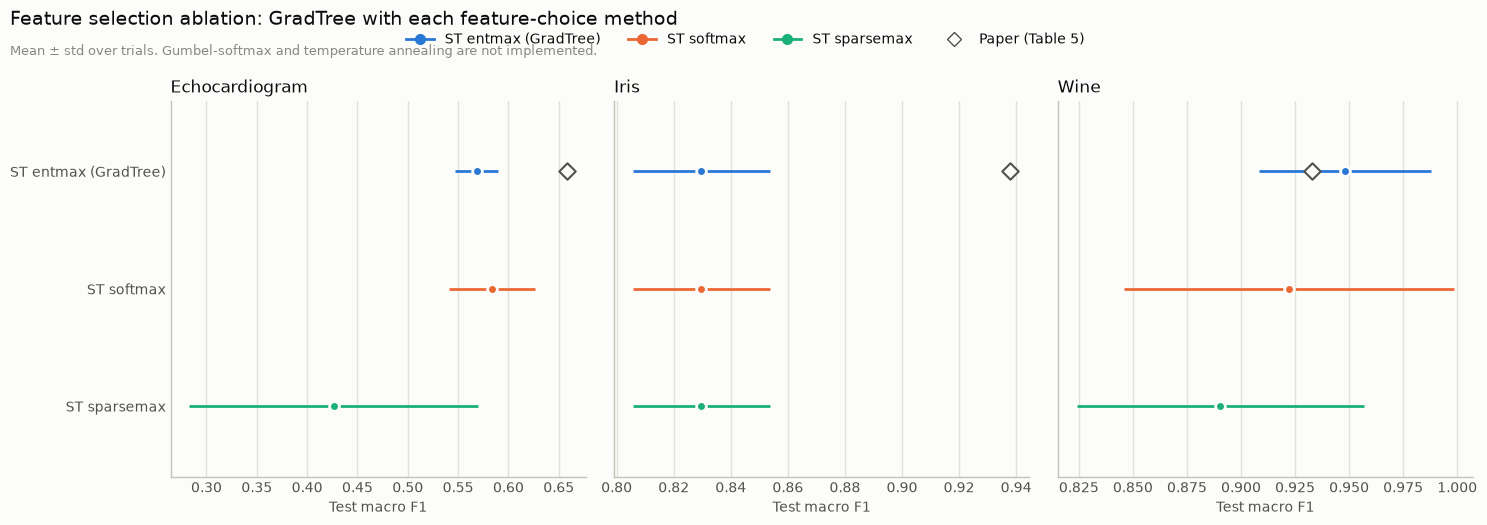

In [ ]:
df = read_results()
ablation_df = df[df["experiment"] == "ablation"] if not df.empty else df

if ablation_df.empty:
    print("No ablation results yet. Set RUN_ABLATION = True and run the experiment cell.")
else:
    ablation_summary = summarize(ablation_df, ["dataset", "activation"])
    y_positions = {
        activation: len(ABLATION_ACTIVATIONS) - 1 - i
        for i, activation in enumerate(ABLATION_ACTIVATIONS)
    }
    fig, axes = plt.subplots(1, len(ABLATION_DATASETS), figsize=(15, 5), sharey=True)
    fig.patch.set_facecolor(SURFACE)
    if len(ABLATION_DATASETS) == 1:
        axes = [axes]

    for ax, dataset in zip(axes, ABLATION_DATASETS):
        for activation in ABLATION_ACTIVATIONS:
            row = ablation_summary[
                (ablation_summary["dataset"] == dataset)
                & (ablation_summary["activation"] == activation)
            ]
            if row.empty:
                continue
            mean = float(row["test_macro_f1_mean"].iloc[0])
            std = float(row["test_macro_f1_std"].iloc[0])
            color = ACT_COLORS[activation]
            ax.errorbar(
                mean, y_positions[activation], xerr=std, fmt="o",
                color=color, ecolor=color, elinewidth=2, capsize=0,
                markersize=7, markeredgecolor=SURFACE, markeredgewidth=2,
                zorder=3,
            )
        if dataset in PAPER_TEST_F1:
            paper_mean, _ = PAPER_TEST_F1[dataset]
            ax.scatter(
                paper_mean, y_positions["entmax"], marker="D", s=70,
                facecolors=SURFACE, edgecolors=PAPER, linewidths=1.5, zorder=5,
            )
        style_axes(ax, grid_axis="x")
        ax.set_title(DATASET_LABELS[dataset], color=INK, fontsize=12, loc="left")
        ax.set_xlabel("Test macro F1", color=INK_2)
        ax.set_yticks(list(y_positions.values()))
        ax.set_yticklabels([ABLATION_LABELS[a] for a in ABLATION_ACTIVATIONS])
        ax.set_ylim(-0.6, len(ABLATION_ACTIVATIONS) - 0.4)

    handles = [
        Line2D([0], [0], color=ACT_COLORS[a], marker="o", lw=2, markersize=7, label=ABLATION_LABELS[a])
        for a in ABLATION_ACTIVATIONS
    ]
    handles.append(
        Line2D([0], [0], color=PAPER, marker="D", markerfacecolor=SURFACE, lw=0, markersize=7, label="Paper (Table 5)")
    )
    fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(
        "Feature selection ablation: GradTree with each feature-choice method",
        x=0.01, y=1.04, ha="left", color=INK, fontsize=14,
    )
    fig.text(
        0.01, 0.95,
        "Mean ± std over trials. Gumbel-softmax and temperature annealing are not implemented.",
        color=MUTED, fontsize=9, ha="left",
    )
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fig_feature_selection_ablation.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
    plt.show()


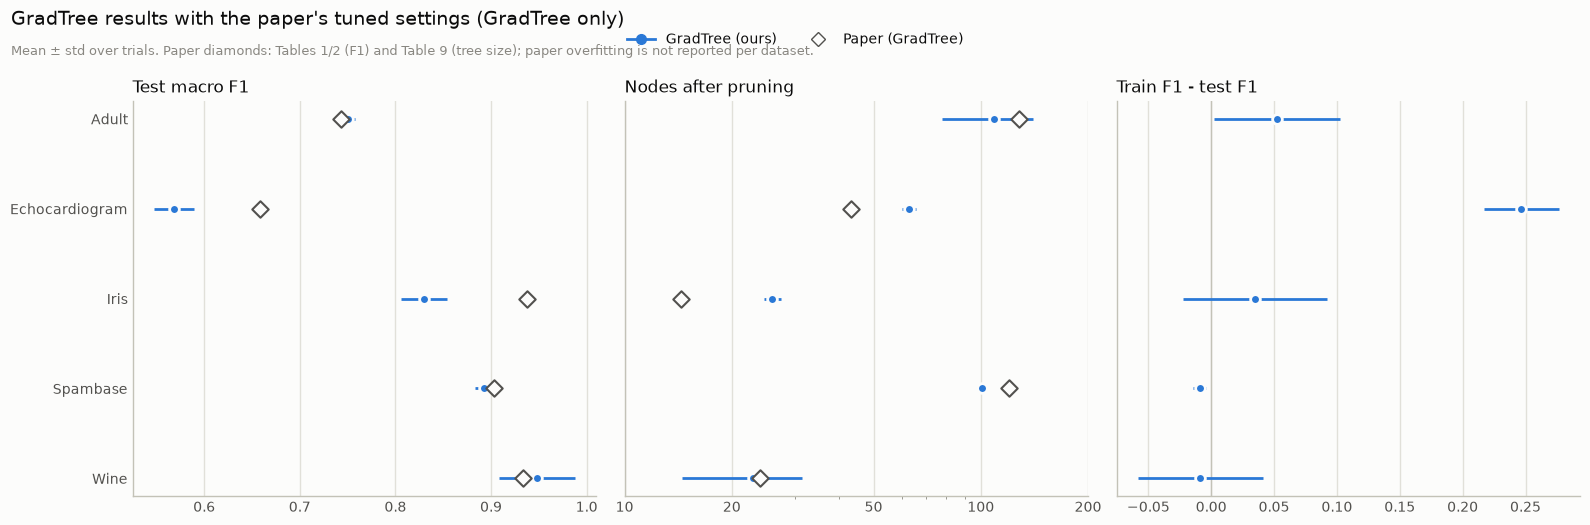

In [ ]:
df = read_results()
main_df = df[df["experiment"] == "main"] if not df.empty else df

if main_df.empty:
    print("No main results yet. Set RUN_MAIN = True and run the experiment cell.")
else:
    summary = summarize(main_df, ["dataset"])
    summary["dataset"] = pd.Categorical(summary["dataset"], categories=DATASETS, ordered=True)
    summary = summary.sort_values("dataset")

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
    fig.patch.set_facecolor(SURFACE)
    y_map = {dataset: len(DATASETS) - 1 - i for i, dataset in enumerate(DATASETS)}
    panels = [
        ("test_macro_f1_mean", "test_macro_f1_std", "Test macro F1", False, "test"),
        ("tree_nodes_mean", "tree_nodes_std", "Nodes after pruning", True, "size"),
        ("overfitting_mean", "overfitting_std", "Train F1 - test F1", False, None),
    ]

    for ax, (mean_col, std_col, title, log_x, paper_key) in zip(axes, panels):
        for dataset in DATASETS:
            row = summary[summary["dataset"] == dataset]
            if row.empty:
                continue
            y = y_map[dataset]
            mean = float(row[mean_col].iloc[0])
            std = float(row[std_col].iloc[0])
            ax.errorbar(
                mean, y, xerr=std, fmt="o", color=BLUE, ecolor=BLUE,
                elinewidth=2, capsize=0, markersize=7,
                markeredgecolor=SURFACE, markeredgewidth=2, zorder=3,
            )
            if paper_key == "test" and dataset in PAPER_TEST_F1:
                paper_mean, _ = PAPER_TEST_F1[dataset]
                ax.scatter(
                    paper_mean, y, marker="D", s=70, facecolors=SURFACE,
                    edgecolors=PAPER, linewidths=1.5, zorder=5,
                )
            if paper_key == "size" and dataset in PAPER_TREE_SIZE:
                paper_mean, _ = PAPER_TREE_SIZE[dataset]
                ax.scatter(
                    paper_mean, y, marker="D", s=70, facecolors=SURFACE,
                    edgecolors=PAPER, linewidths=1.5, zorder=5,
                )
        if log_x:
            ax.set_xscale("log")
            ax.set_xticks([10, 20, 50, 100, 200])
            ax.xaxis.set_major_formatter(ScalarFormatter())
            ax.xaxis.set_minor_formatter(NullFormatter())
        if title.startswith("Train F1"):
            ax.axvline(0.0, color=AXIS, lw=1, zorder=1)
        style_axes(ax, grid_axis="x")
        ax.set_title(title, color=INK, fontsize=12, loc="left")
        ax.set_yticks(list(y_map.values()))
        ax.set_yticklabels([DATASET_LABELS[d] for d in DATASETS])

    handles = [
        Line2D([0], [0], color=BLUE, marker="o", lw=2, markersize=7, label="GradTree (ours)"),
        Line2D([0], [0], color=PAPER, marker="D", markerfacecolor=SURFACE, lw=0, markersize=7, label="Paper (GradTree)"),
    ]
    fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(
        "GradTree results with the paper's tuned settings (GradTree only)",
        x=0.01, y=1.04, ha="left", color=INK, fontsize=14,
    )
    fig.text(
        0.01, 0.95,
        "Mean ± std over trials. Paper diamonds: Tables 1/2 (F1) and Table 9 (tree size); "
        "paper overfitting is not reported per dataset.",
        color=MUTED, fontsize=9, ha="left",
    )
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fig_main_results.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
    plt.show()


In [ ]:
df = read_results()
main_df = df[df["experiment"] == "main"] if not df.empty else df
has_ranking = (
    not main_df.empty
    and "mrr_test" in main_df.columns
    and main_df["mrr_test"].notna().any()
)

if not has_ranking:
    print(
        "No ranking metrics yet. MRR/MRD are stored for trials trained with the "
        "current experiments.py; rows cached from an older version do not have them. "
        "Delete those rows from results/runs.csv to retrain them with MRR/MRD."
    )
else:
    summary = summarize(main_df, ["dataset"])
    summary["dataset"] = pd.Categorical(summary["dataset"], categories=DATASETS, ordered=True)
    summary = summary.sort_values("dataset").reset_index(drop=True)

    # Train-vs-test table: F1 plus the two ranking metrics.
    table = pd.DataFrame({
        "dataset": summary["dataset"].astype(str),
        "trials": summary["n"],
        "train_f1": summary["train_macro_f1_mean"],
        "test_f1": summary["test_macro_f1_mean"],
        "f1_gap": summary["train_macro_f1_mean"] - summary["test_macro_f1_mean"],
        "train_mrr": summary["mrr_train_mean"],
        "test_mrr": summary["mrr_test_mean"],
        "mrr_gap": summary["mrr_train_mean"] - summary["mrr_test_mean"],
        "train_mrd": summary["mrd_train_mean"],
        "test_mrd": summary["mrd_test_mean"],
        "mrd_gap": summary["mrd_test_mean"] - summary["mrd_train_mean"],
    })
    table.to_csv(RESULTS_DIR / "summary_train_vs_test.csv", index=False)
    print("Train vs test performance (mean over trials)")
    display(table)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    fig.patch.set_facecolor(SURFACE)
    y_map = {dataset: len(DATASETS) - 1 - i for i, dataset in enumerate(DATASETS)}
    panels = [
        ("mrr_train_mean", "mrr_train_std", "mrr_test_mean", "mrr_test_std",
         "MRR (higher is better)"),
        ("mrd_train_mean", "mrd_train_std", "mrd_test_mean", "mrd_test_std",
         "MRD (lower is better)"),
    ]

    for ax, (train_mean, train_std, test_mean, test_std, title) in zip(axes, panels):
        for dataset in DATASETS:
            row = summary[summary["dataset"] == dataset]
            if row.empty:
                continue
            y = y_map[dataset]
            for mean_col, std_col, color in (
                (train_mean, train_std, ORANGE),
                (test_mean, test_std, BLUE),
            ):
                mean = float(row[mean_col].iloc[0])
                std = float(row[std_col].iloc[0])
                ax.errorbar(
                    mean, y, xerr=std, fmt="o", color=color, ecolor=color,
                    elinewidth=2, capsize=0, markersize=7,
                    markeredgecolor=SURFACE, markeredgewidth=2, zorder=3,
                )
        style_axes(ax, grid_axis="x")
        ax.set_title(title, color=INK, fontsize=12, loc="left")
        ax.set_yticks(list(y_map.values()))
        ax.set_yticklabels([DATASET_LABELS[d] for d in DATASETS])

    handles = [
        Line2D([0], [0], color=BLUE, marker="o", lw=2, markersize=7, label="Test"),
        Line2D([0], [0], color=ORANGE, marker="o", lw=2, markersize=7, label="Train"),
    ]
    fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False,
               bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(
        "Train vs test ranking performance (mean ± std over trials)",
        x=0.01, y=1.04, ha="left", color=INK, fontsize=14,
    )
    fig.text(
        0.01, 0.95,
        "MRR = mean 1/rank of the true class; MRD = mean (rank − 1). "
        "Larger train/test separation means more overfitting.",
        color=MUTED, fontsize=9, ha="left",
    )
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fig_train_vs_test.png", dpi=200,
                bbox_inches="tight", facecolor=SURFACE)
    plt.show()


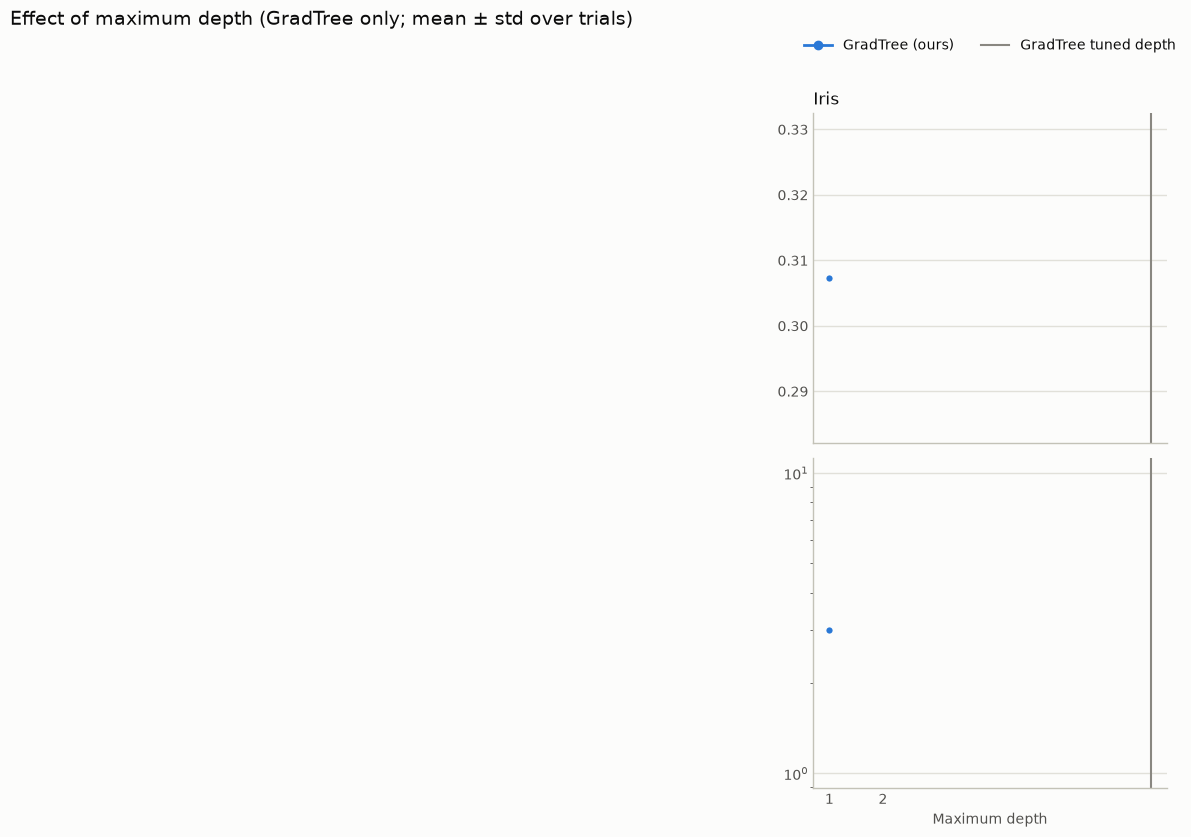

In [ ]:
df = read_results()
depth_df = df[df["experiment"] == "depth"] if not df.empty else df

if depth_df.empty:
    print("No depth-sweep results yet. Set RUN_DEPTH_SWEEP = True and run the experiment cell.")
else:
    depth_summary = summarize(depth_df, ["dataset", "depth"])
    fig, axes = plt.subplots(2, len(DATASETS), figsize=(20, 8), sharex=True)
    fig.patch.set_facecolor(SURFACE)

    for col, dataset in enumerate(DATASETS):
        ax_top = axes[0, col]
        ax_bottom = axes[1, col]
        subset = depth_summary[depth_summary["dataset"] == dataset].sort_values("depth")
        if subset.empty:
            ax_top.set_visible(False)
            ax_bottom.set_visible(False)
            continue

        depths = subset["depth"].astype(int).to_numpy()
        f1_mean = subset["test_macro_f1_mean"].to_numpy(dtype=float)
        f1_std = subset["test_macro_f1_std"].to_numpy(dtype=float)
        size_mean = subset["tree_nodes_mean"].to_numpy(dtype=float)
        size_std = subset["tree_nodes_std"].to_numpy(dtype=float)

        ax_top.plot(
            depths, f1_mean, color=BLUE, lw=2, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3,
        )
        ax_top.fill_between(
            depths, f1_mean - f1_std, f1_mean + f1_std,
            color=BLUE, alpha=0.16, linewidth=0, zorder=2,
        )

        ax_bottom.plot(
            depths, size_mean, color=BLUE, lw=2, marker="o", markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3,
        )
        ax_bottom.fill_between(
            depths, np.maximum(size_mean - size_std, 0.5), size_mean + size_std,
            color=BLUE, alpha=0.16, linewidth=0, zorder=2,
        )
        ax_bottom.set_yscale("log")

        tuned_depth = PAPER_SETTINGS[dataset]["depth"]
        line_kwargs = dict(color=MUTED, lw=1.5, zorder=1)
        if col == 0:
            line_kwargs["label"] = "GradTree tuned depth"
        ax_top.axvline(tuned_depth, **line_kwargs)
        ax_bottom.axvline(tuned_depth, **line_kwargs)

        style_axes(ax_top, grid_axis="y")
        style_axes(ax_bottom, grid_axis="y")
        ax_top.set_title(DATASET_LABELS[dataset], color=INK, fontsize=12, loc="left")
        ax_bottom.set_xticks(DEPTHS)
        ax_bottom.set_xlabel("Maximum depth", color=INK_2)
        if col == 0:
            ax_top.set_ylabel("Test macro F1", color=INK_2)
            ax_bottom.set_ylabel("Tree size (nodes, log scale)", color=INK_2)

    handles = [
        Line2D([0], [0], color=BLUE, marker="o", lw=2, markersize=6, label="GradTree (ours)"),
        Line2D([0], [0], color=MUTED, lw=1.5, label="GradTree tuned depth"),
    ]
    fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(
        "Effect of maximum depth (GradTree only; mean ± std over trials)",
        x=0.01, y=1.04, ha="left", color=INK, fontsize=14,
    )
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fig_depth_sweep.png", dpi=200, bbox_inches="tight", facecolor=SURFACE)
    plt.show()


# Notes and caveats

- **Scope:** GradTree only. CART and Random Forest are intentionally omitted, as requested.
- **Quick vs paper protocol:** `QUICK_RUN = True` uses 2 seeds and short training to validate the notebook. Set `QUICK_RUN = False` for the paper protocol: 10 seeds, 10,000 epochs, patience 200, 3 restarts.
- **Caching:** every run is appended to `model/sunny/results/runs.csv`, scoped to `PROTOCOL` (quick/paper, epochs, patience, restarts, and a hash of `PAPER_SETTINGS`). Changing those settings creates a new cache scope. Delete `runs.csv` to force a full rerun. New metrics are stored as extra columns, so rows cached before a metric existed are still reused — they simply show `NaN` for that metric.
- **Parallelism:** `JOBS` trials run at once in separate worker processes. The training code must live in `model/sunny/experiments.py` for that to work, because a worker re-imports its target by module reference. Rows are appended as each worker finishes, so stopping the kernel loses at most the trials still running.
- **`fit_seconds`:** each row records how long its trial took, so you can compute the expected wall clock of a sweep (`sum(fit_seconds) / JOBS`) instead of guessing.
- **MRR (mean reciprocal rank):** rank the classes by predicted probability, then `1 / rank` of the true class, averaged over rows. Higher is better; 1.0 is perfect.
- **MRD (mean rank difference):** the same ranks, averaged as `rank − 1`, i.e. how many classes are ranked above the true one. Lower is better; 0 is perfect. MRR and MRD are two views of one ranking, so `MRD ≈ 1/MRR − 1` only when every row has the same rank.
- **Binary caveat:** with two classes the rank is 1 or 2, so `MRR` equals accuracy and `MRD = 1 − accuracy`. The ranking metrics only add information beyond F1 for Iris and Wine (three classes each). Their real value here is the train-vs-test comparison, which F1 also gives — so read the two together.
- **Train vs test:** `overfitting` is `train macro F1 − test macro F1` per trial. The train-vs-test cell adds MRR and MRD versions (`mrr_gap`, `mrd_gap`), writes `results/summary_train_vs_test.csv`, and saves `fig_train_vs_test.png`. Per-row probabilities of every main trial are written to `results/predictions/<dataset>_seed_<seed>.csv`, so the ranking metrics can be recomputed without retraining.
- **Feature-selection ablation:** this implementation supports `entmax`, `softmax`, and `sparsemax`. The paper's Gumbel-softmax and temperature-annealing variants are not implemented, so they are not shown.
- **Ablation cost:** the `entmax` column of the ablation re-trains trials that the main grid already produced (the cache key includes `experiment`). If you only need the figure, consider running the ablation on fewer datasets or seeds.
- **Paper values:** test macro F1 from Tables 1/2, tree size from Table 9, tuned depth/settings from Table 12, and ST-entmax ablation values from Table 5. Paper overfitting is not reported per dataset, so no paper diamonds are drawn in the overfitting panel.
- **Test metric:** each trial uses the test split belonging to its data seed (42 + trial), with model seed 42. Per-dataset mean/std is over trials; the paper does not average macro F1 across datasets.
- **Data requirement:** all five datasets need `preprocess/<dataset>_output/seed_42` through `seed_51`. The dataset-check cell reports missing folders.